In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from qutip import Qobj, spre, spost, qeye, sigmax, sigmay, sigmaz, qpt
# --- Pauli basis for QPT --- #
pauli_basis = [qeye(2), sigmax(), sigmay(), sigmaz()]
op_basis = [pauli_basis, pauli_basis]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
                   'XI', 'XX', 'XY', 'XZ',
                   'YI', 'YX', 'YY', 'YZ',
                   'ZI', 'ZX', 'ZY', 'ZZ']
# --- Define PTM labels --- #
ptm_labels = pauli_labels_2q
# --- Ideal ZZ unitary definition --- #
def zz_unitary(theta):
    return np.diag([
        -np.exp(-1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(1j * theta / 2),
        -np.exp(-1j * theta / 2)
    ])
# --- Convert unitary to PTM --- #
def unitary_to_ptm(U: Qobj):
    paulis = [qeye(2), sigmax(), sigmay(), sigmaz()]
    basis = [Qobj(np.kron(p1.full(), p2.full())) for p1 in paulis for p2 in paulis]
    T = np.zeros((16, 16), dtype=np.complex128)
    for i, Pi in enumerate(basis):
        rho_out = U * Pi * U.dag()
        for j, Pj in enumerate(basis):
            T[j, i] = (Pj.dag() * rho_out).tr() / 4
    return T


In [2]:
def zz_unitary(theta):
    return np.diag([
        -np.exp(-1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(-1j * theta / 2)
    ])

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

def dme_heisenberg(phi):
    ZZ_phi = zz_unitary(phi)
    YY_phi = np.kron(S_dagger,I) @ np.kron(H,I) @ np.kron(I,S_dagger) @ np.kron(I,H) @ zz_unitary(phi) @ np.kron(H,I) @ np.kron(S,I) @ np.kron(I,H) @ np.kron(I,S)
    XX_phi = np.kron(H,I) @ np.kron(I,H) @ zz_unitary(phi) @ np.kron(H,I) @ np.kron(I,H)
    return ZZ_phi @ XX_phi @ YY_phi 


In [3]:
zz_unitary(0)

array([[-1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j],
       [ 0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j],
       [ 0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j],
       [ 0.+0.j,  0.+0.j,  0.+0.j,  1.-0.j]])

In [4]:
np.kron(I,Z) @ np.kron(Z,I) @ zz_unitary(0)

array([[-1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j],
       [ 0.+0.j, -1.+0.j,  0.+0.j,  0.+0.j],
       [ 0.+0.j,  0.+0.j, -1.+0.j,  0.+0.j],
       [ 0.+0.j,  0.+0.j,  0.+0.j,  1.+0.j]])

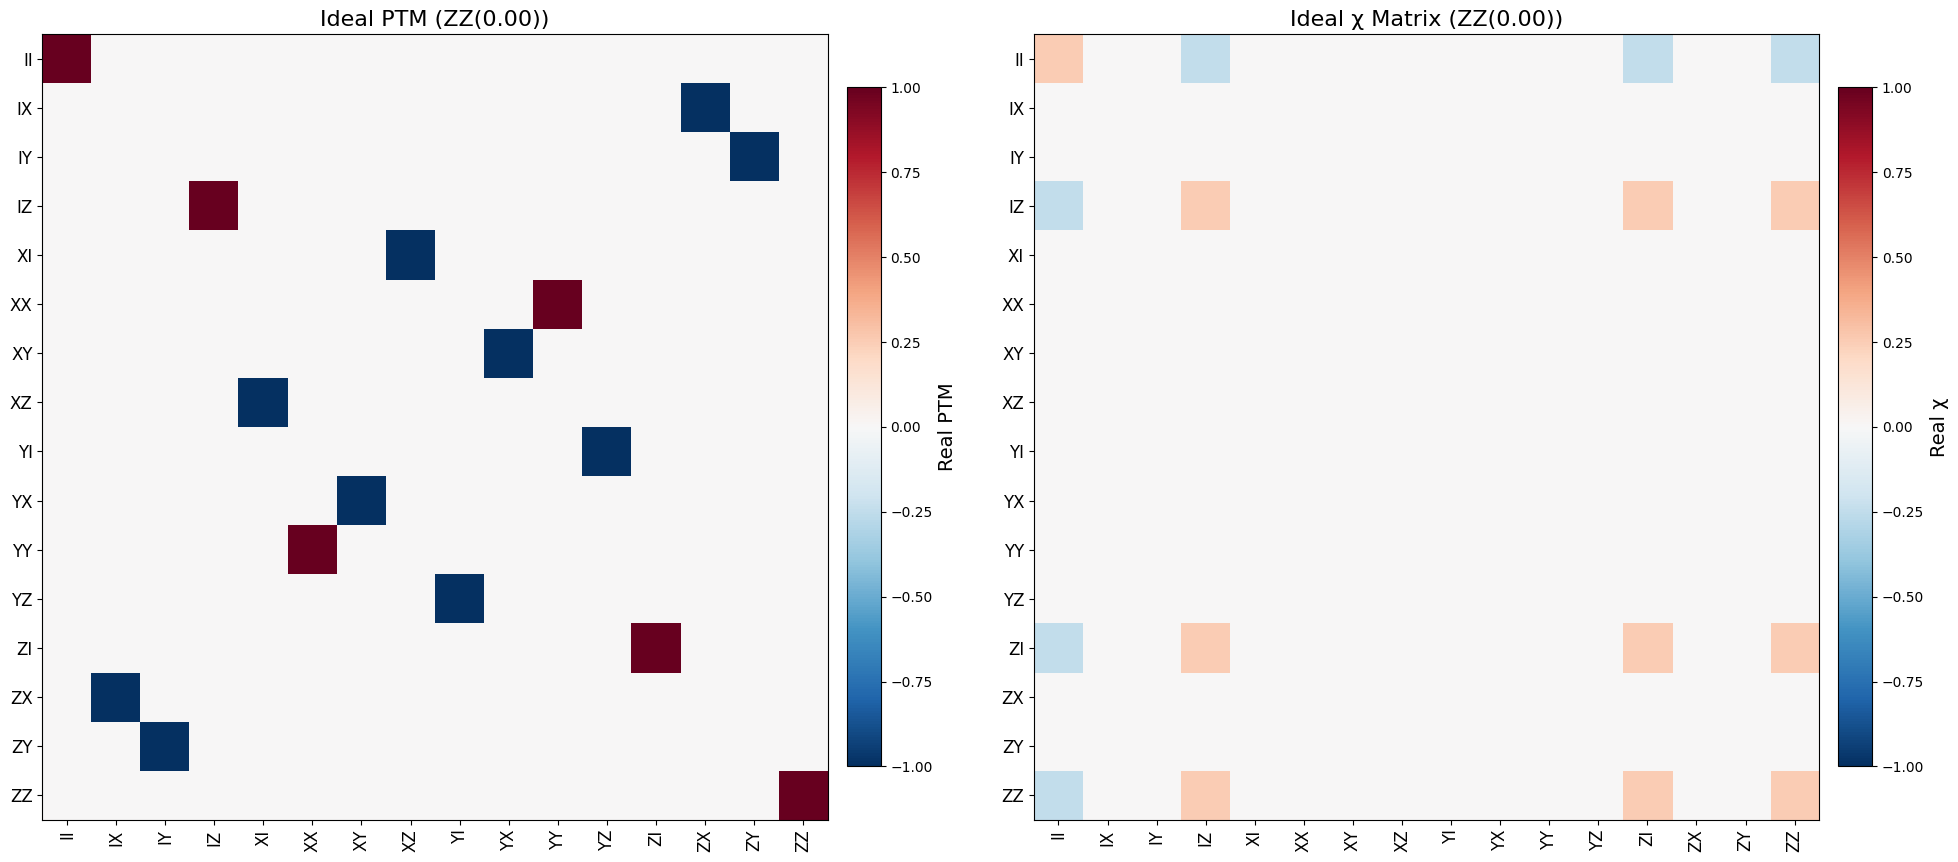

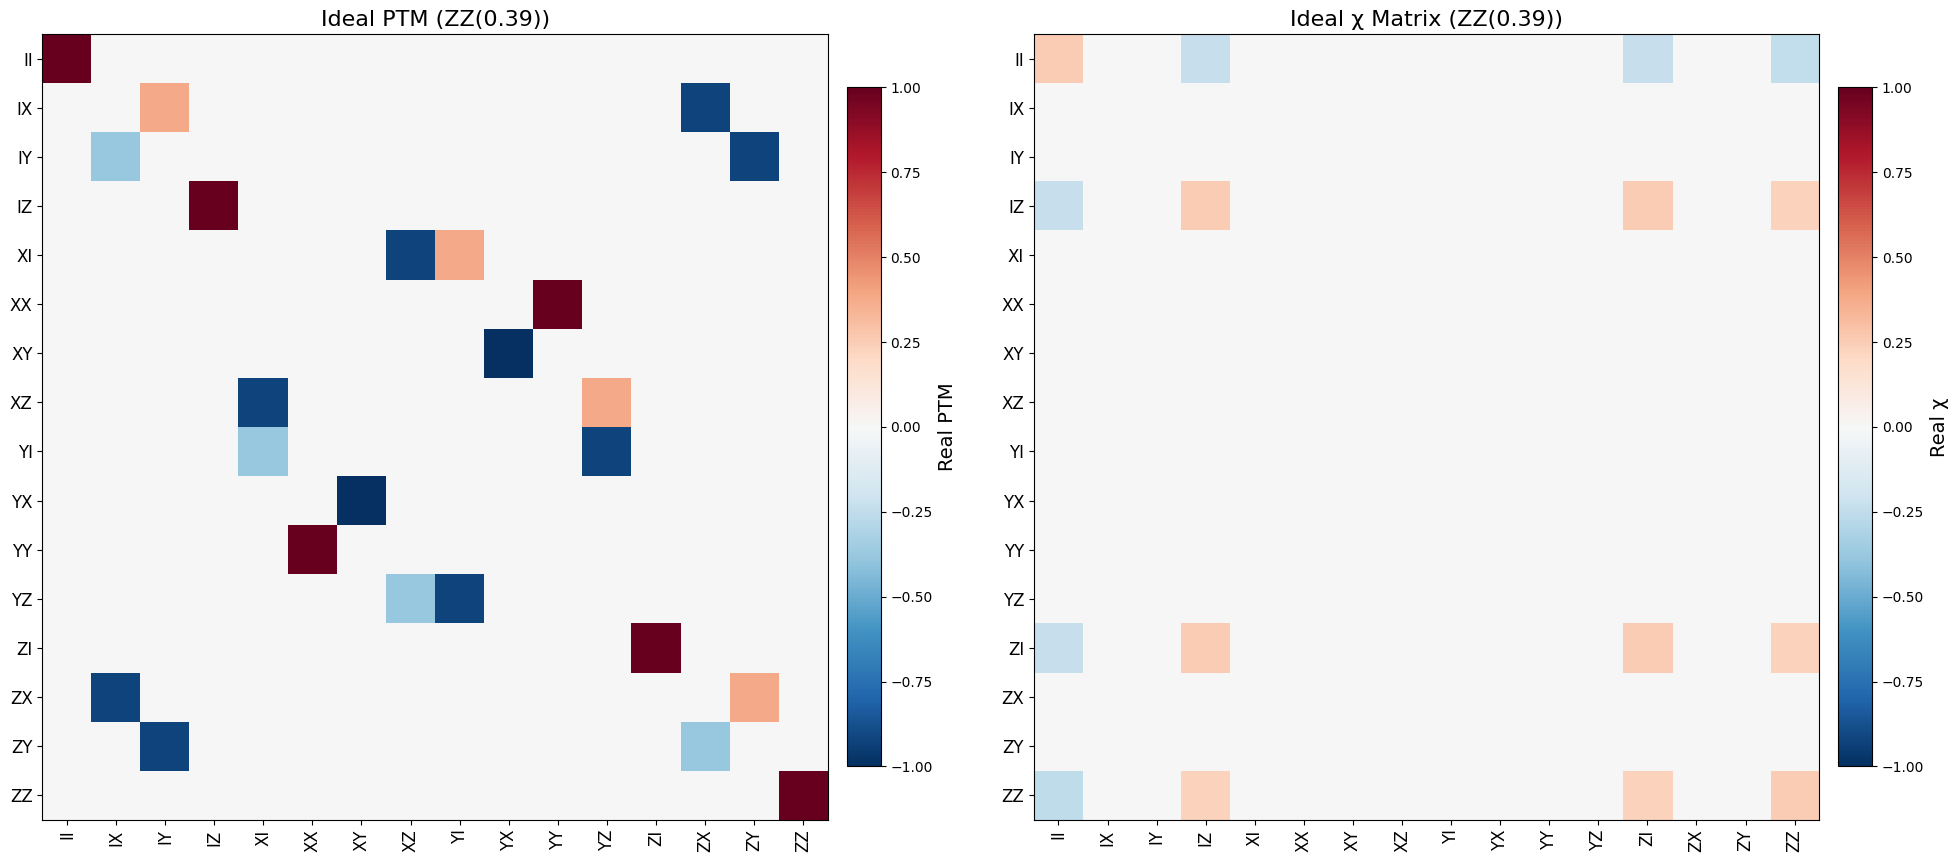

In [5]:
# --- Theta values to sweep over --- #
theta_list = [0, np.pi/8]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(zz_unitary(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    chi_ideal = qpt(spre(U_ideal) * spost(U_ideal.dag()), op_basis)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    # PTM plot
    cax1 = ax1.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax1.set_xticks(np.arange(16))
    ax1.set_yticks(np.arange(16))
    ax1.set_xticklabels(ptm_labels, rotation=90, fontsize=12)
    ax1.set_yticklabels(ptm_labels, fontsize=12)
    ax1.set_title(f"Ideal PTM (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # χ matrix plot
    cax2 = ax2.imshow(np.real(chi_ideal), cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax2.set_xticks(np.arange(16))
    ax2.set_yticks(np.arange(16))
    ax2.set_xticklabels(pauli_labels_2q, rotation=90, fontsize=12)
    ax2.set_yticklabels(pauli_labels_2q, fontsize=12)
    ax2.set_title(f"Ideal χ Matrix (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # Colorbars
    fig.colorbar(cax1, ax=ax1, shrink=0.7, pad=0.02).set_label("Real PTM", fontsize=14)
    fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)
    plt.tight_layout()
    plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_30520\2869882405.py:25: UserWarning: Adding colorbar to a different Figure <Figure size 2000x1000 with 6 Axes> than <Figure size 500x500 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)


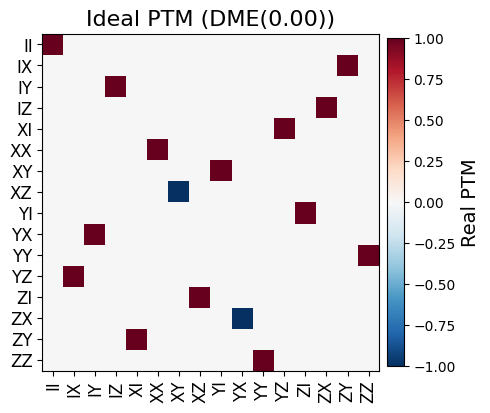

C:\Users\Admin\AppData\Local\Temp\ipykernel_30520\2869882405.py:25: UserWarning: Adding colorbar to a different Figure <Figure size 2000x1000 with 7 Axes> than <Figure size 500x500 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)


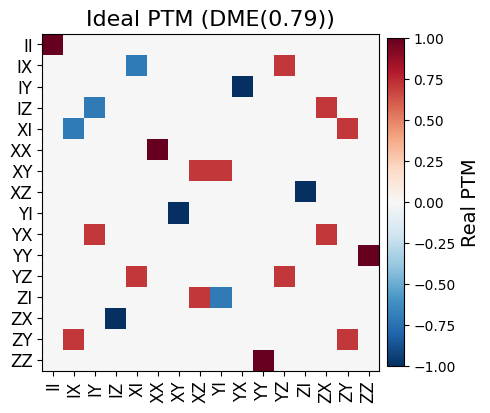

C:\Users\Admin\AppData\Local\Temp\ipykernel_30520\2869882405.py:25: UserWarning: Adding colorbar to a different Figure <Figure size 2000x1000 with 8 Axes> than <Figure size 500x500 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)


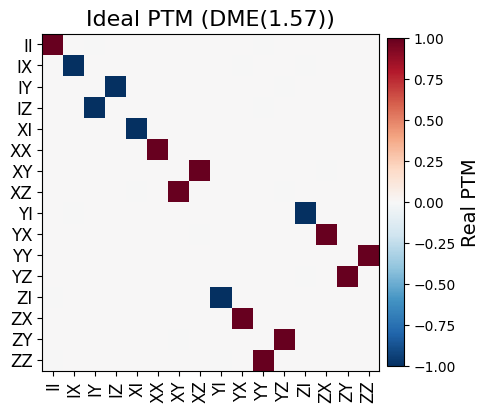

In [17]:
# --- Theta values to sweep over --- #
theta_list = [0,np.pi/4,np.pi/2]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(dme_heisenberg(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    chi_ideal = qpt(spre(U_ideal) * spost(U_ideal.dag()), op_basis)
    fig, ax1= plt.subplots(1, 1, figsize=(5, 5))
    # PTM plot
    cax1 = ax1.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax1.set_xticks(np.arange(16))
    ax1.set_yticks(np.arange(16))
    ax1.set_xticklabels(ptm_labels, rotation=90, fontsize=12)
    ax1.set_yticklabels(ptm_labels, fontsize=12)
    ax1.set_title(f"Ideal PTM (DME({theta_ZZ:.2f}))", fontsize=16)
    # # χ matrix plot
    # cax2 = ax2.imshow(np.real(chi_ideal), cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    # ax2.set_xticks(np.arange(16))
    # ax2.set_yticks(np.arange(16))
    # ax2.set_xticklabels(pauli_labels_2q, rotation=90, fontsize=12)
    # ax2.set_yticklabels(pauli_labels_2q, fontsize=12)
    # ax2.set_title(f"Ideal χ Matrix (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # Colorbars
    fig.colorbar(cax1, ax=ax1, shrink=0.7, pad=0.02).set_label("Real PTM", fontsize=14)
    fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)
    plt.tight_layout()
    plt.show()

In [7]:
ptm_ideal

array([[ 1.00000000e+00+0.00000000e+00j, -4.91439681e-17+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  1.04814430e-17+0.00000000e+00j,
        -7.36433548e-17+0.00000000e+00j, -8.32667268e-17+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  7.51060464e-18+0.00000000e+00j,
        -1.03352387e-17+0.00000000e+00j, -5.55111512e-17+0.00000000e+00j,
        -8.75211426e-17+0.00000000e+00j,  4.16333634e-17+0.00000000e+00j],
       [ 8.75211426e-17+0.00000000e+00j,  7.36433548e-17+5.55111512e-17j,
         7.51060464e-18-4.25441578e-18j,  0.00000000e+00+0.00000000e+00j,
        -7.07106781e-01+1.38777878e-17j, -7.51060464e-18+0.00000000e+00j,
         3.85185989e-34+0.00000000e+00j,  6.81061329e-18+7.15903769e-18j,
         1.36576440e-17+6.81061329e-18j,  0.00000000e+00+0.00000000e+00j,
         2.13883924e-17+0.00000000e+0

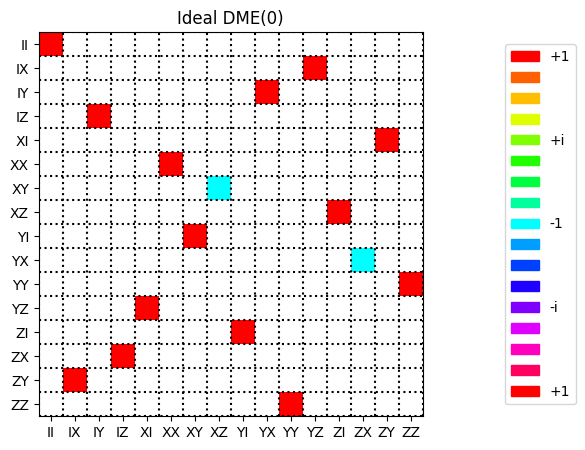

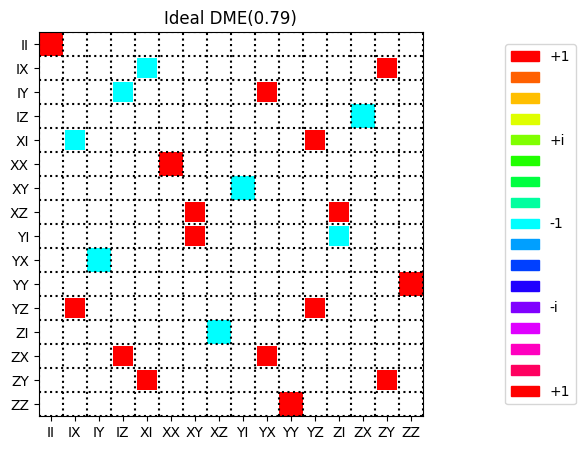

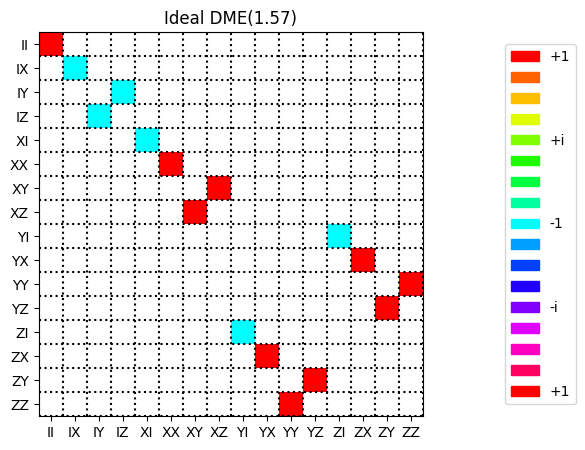

In [8]:
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']
import sys
sys.path.append('..')
from functions.plot_process_matrix import plot_process_matrix
# --- Theta values to sweep over --- #
theta_list = [0, np.pi/4, np.pi/2]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(dme_heisenberg(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    plot_process_matrix(np.asarray(ptm_ideal), pauli_labels_2q,title=f'Ideal DME({np.round(theta_ZZ,2)})')

In [9]:
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']
import sys
sys.path.append('..')
from functions.plot_process_matrix import plot_process_matrix
# --- Theta values to sweep over --- #
theta_list = [0, np.pi/4, np.pi/2]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(dme_heisenberg(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    

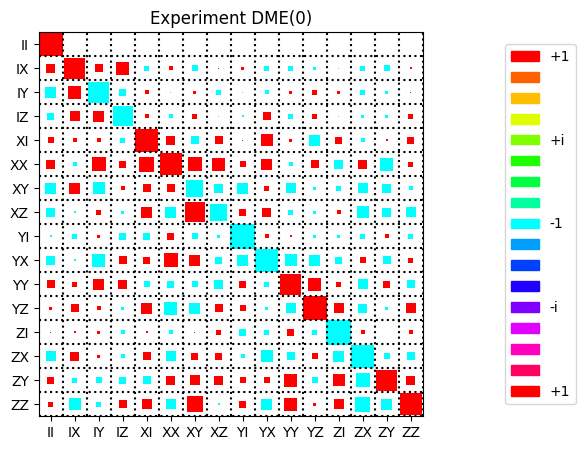

In [10]:
ptm_experiment = np.genfromtxt('ptm_measured_for_DME(0).csv', delimiter=',', skip_header=1)[:, 1:]
plot_process_matrix(np.asarray(ptm_experiment), pauli_labels_2q,title=f'Experiment DME({np.round(0)})')

In [11]:
Z = np.array([[1, 0], [0, -1]])
ZZ = np.kron(Z, Z)
ptm_ZZ = unitary_to_ptm(Qobj(ZZ))

def adjust_for_lab_frame(U):
    correction = ZZ
    return correction @ U @ correction

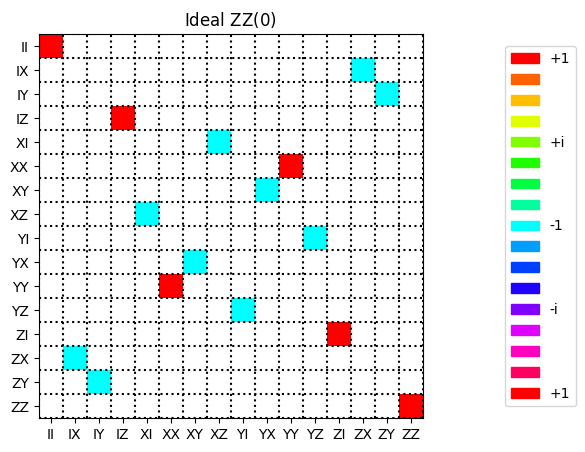

In [12]:
U_ideal = Qobj(zz_unitary(0))
ptm_ideal = unitary_to_ptm(U_ideal)
plot_process_matrix(np.asarray(ptm_ideal), pauli_labels_2q,title=r'Ideal ZZ($0$)')

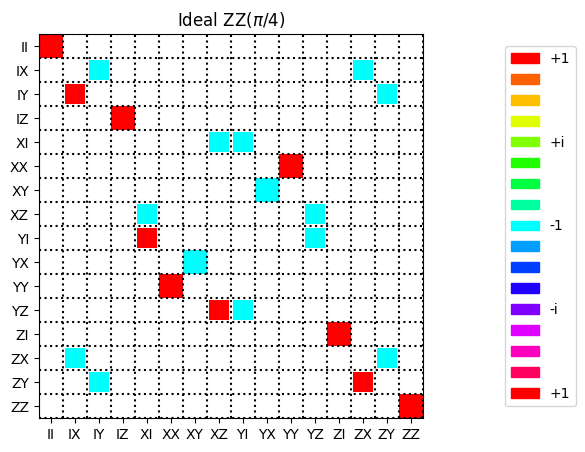

In [13]:
U_ideal = Qobj(zz_unitary(np.pi/4))
ptm_ideal = unitary_to_ptm(U_ideal)
plot_process_matrix(np.asarray(ptm_ideal), pauli_labels_2q,title=r'Ideal ZZ($\pi/4$)')

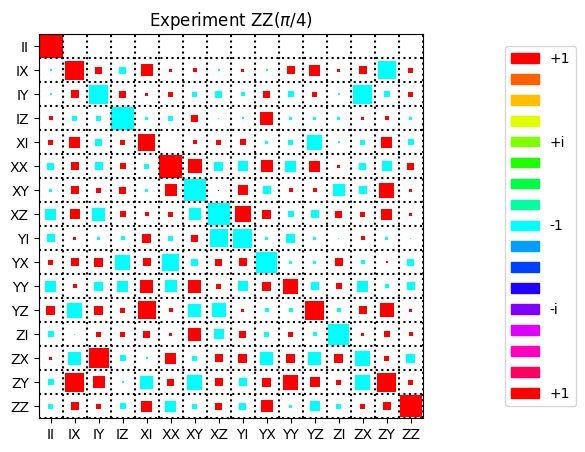

In [14]:
ptm_experiment = np.genfromtxt('ptm_measured_for_ZZ(π4).csv', delimiter=',', skip_header=1)[:, 1:]
plot_process_matrix(np.asarray(ptm_experiment), pauli_labels_2q,title=r'Experiment ZZ($\pi/4$)')

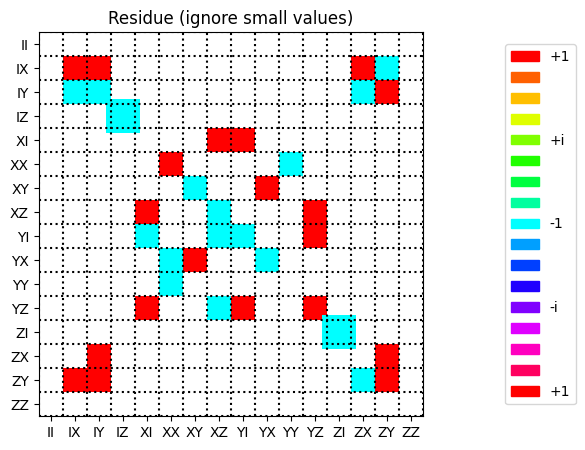

In [15]:
plot_process_matrix(np.round(np.asarray(ptm_experiment-ptm_ideal),0), pauli_labels_2q,title='Residue (ignore small values)')

In [16]:
# --- Theta values to sweep over --- #
theta_list = [0.79]
def RZ(phi):
    return expm(1j*phi*Z)
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(dme_heisenberg(0.79) @ np.kron(I,RZ(0.79)))
    ptm_ideal = unitary_to_ptm(U_ideal)
    plot_process_matrix(np.asarray(ptm_ideal/2), pauli_labels_2q,title=f'Circuit A with DME({np.round(theta_ZZ,2)})')

NameError: name 'expm' is not defined

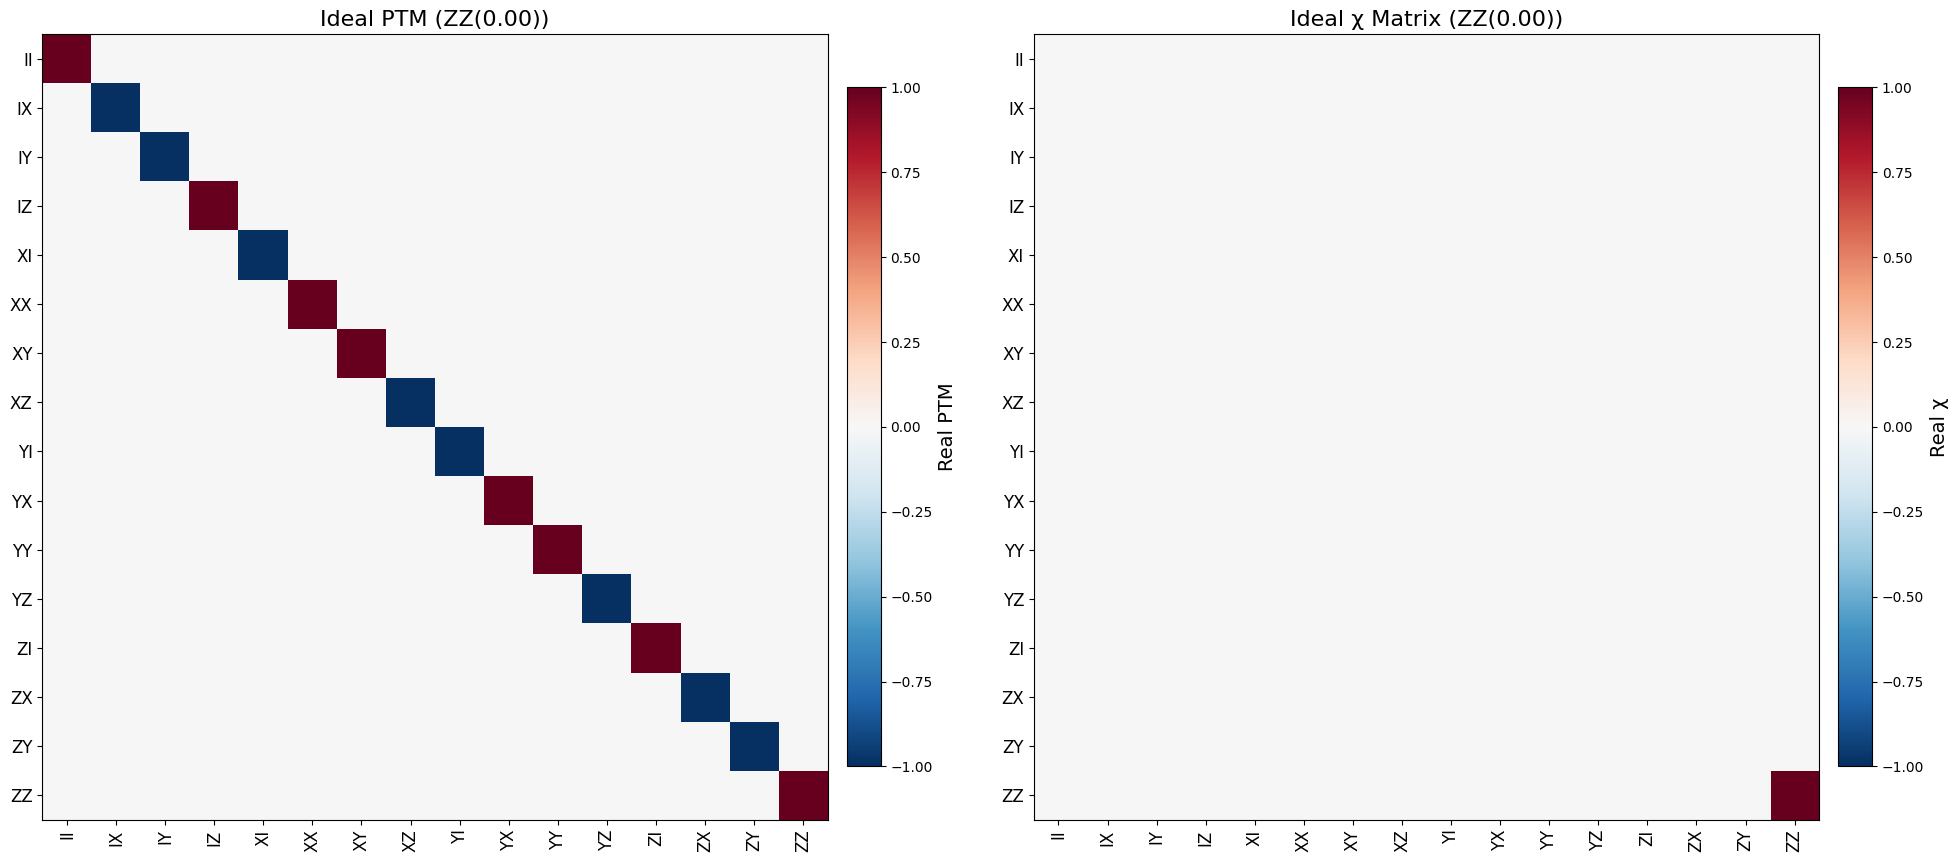

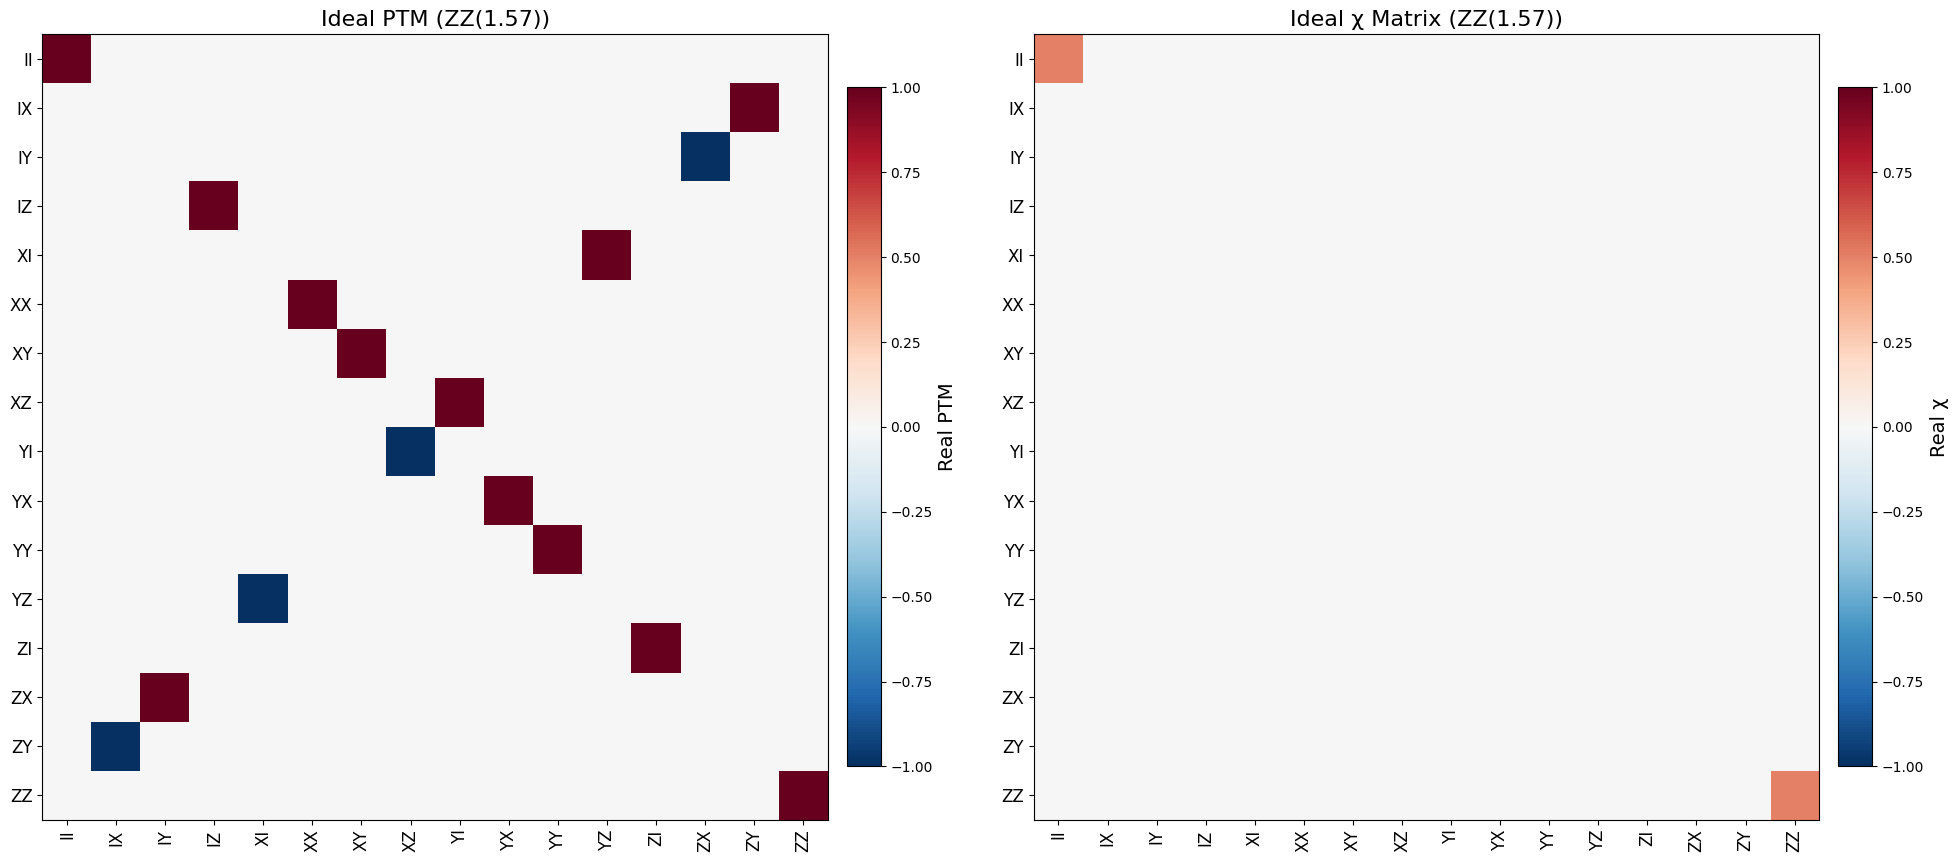

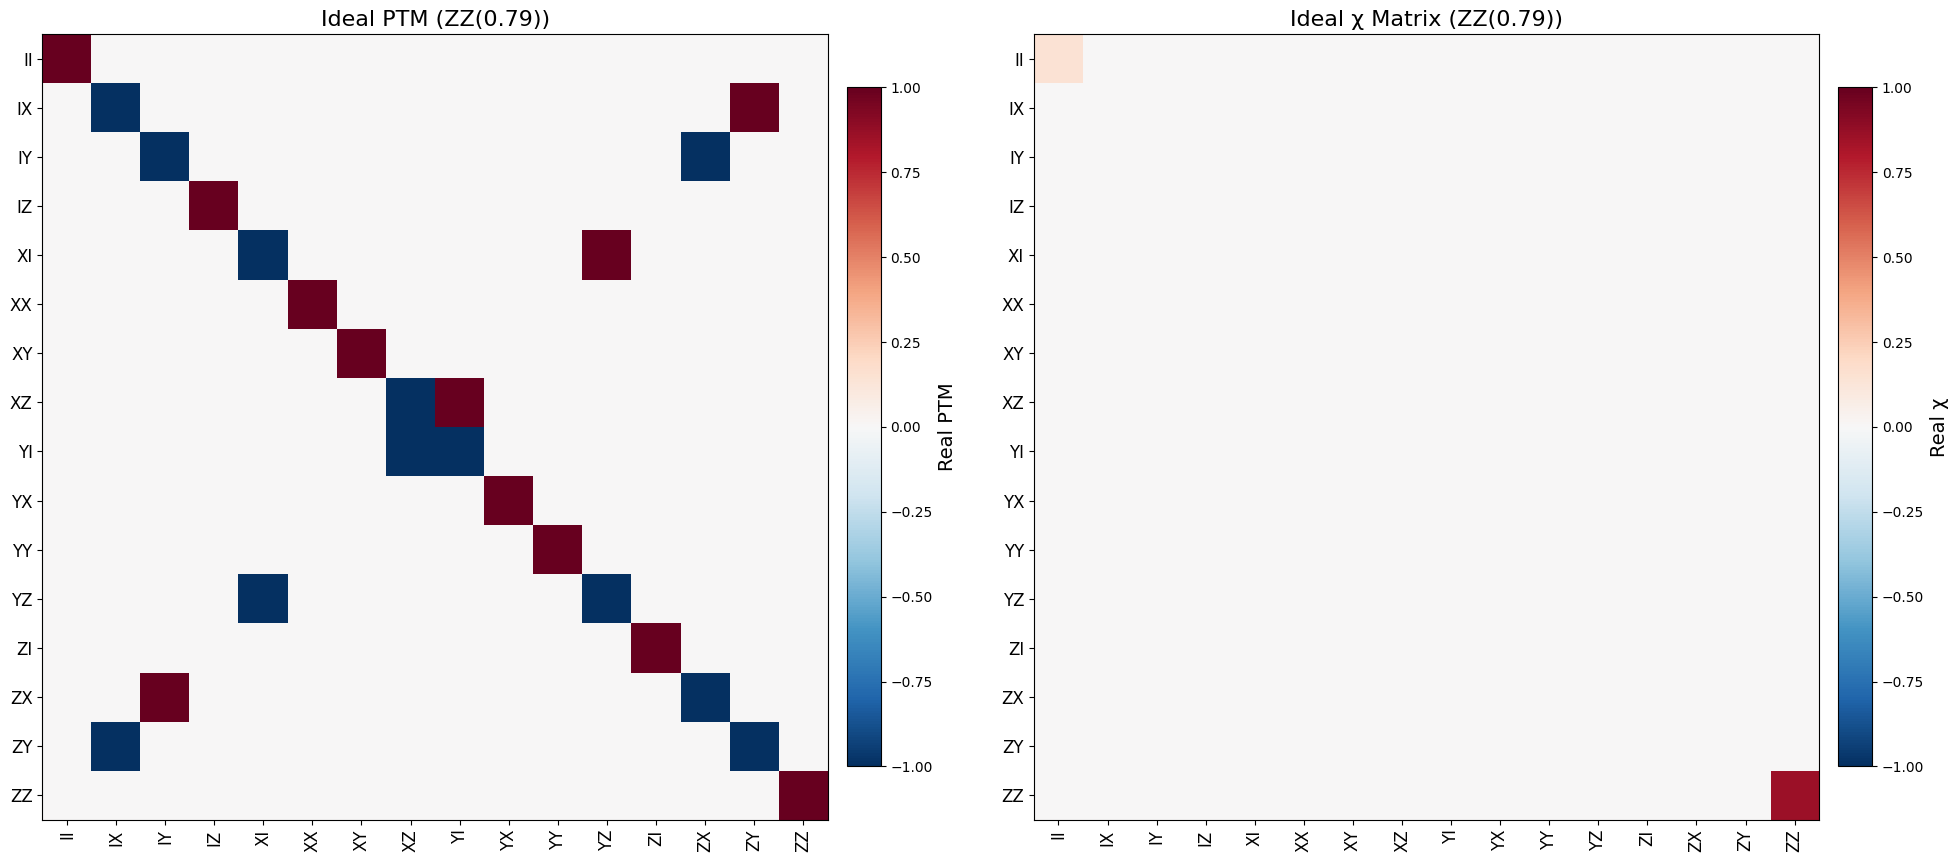

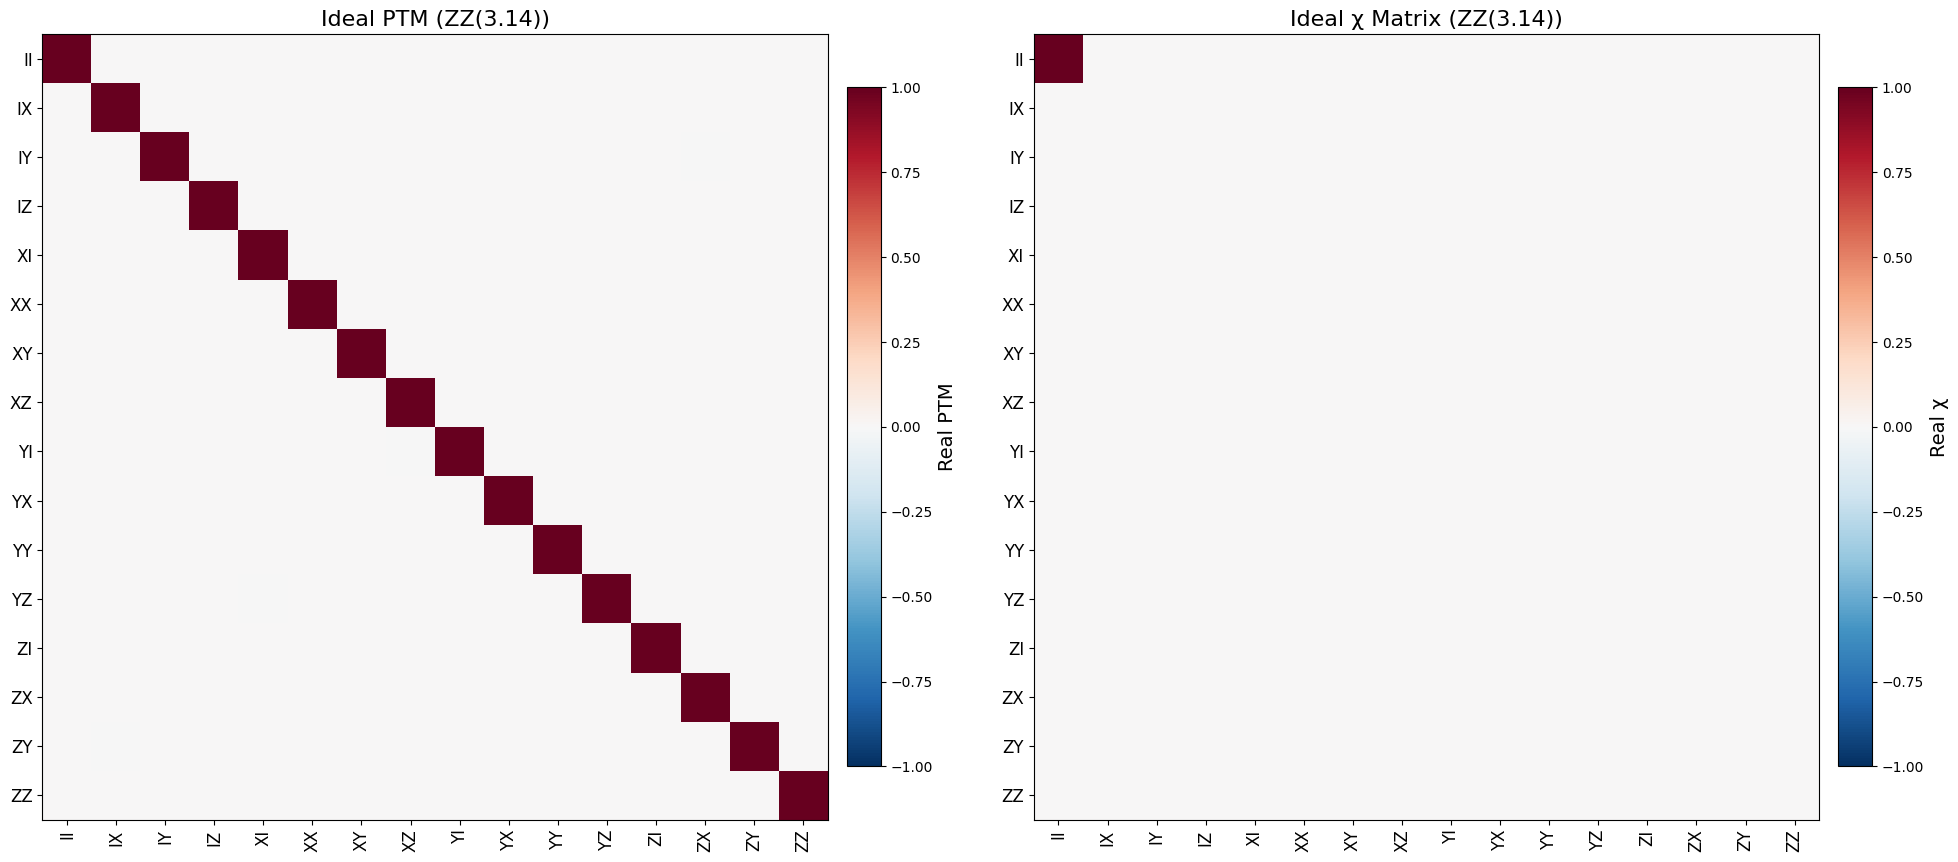

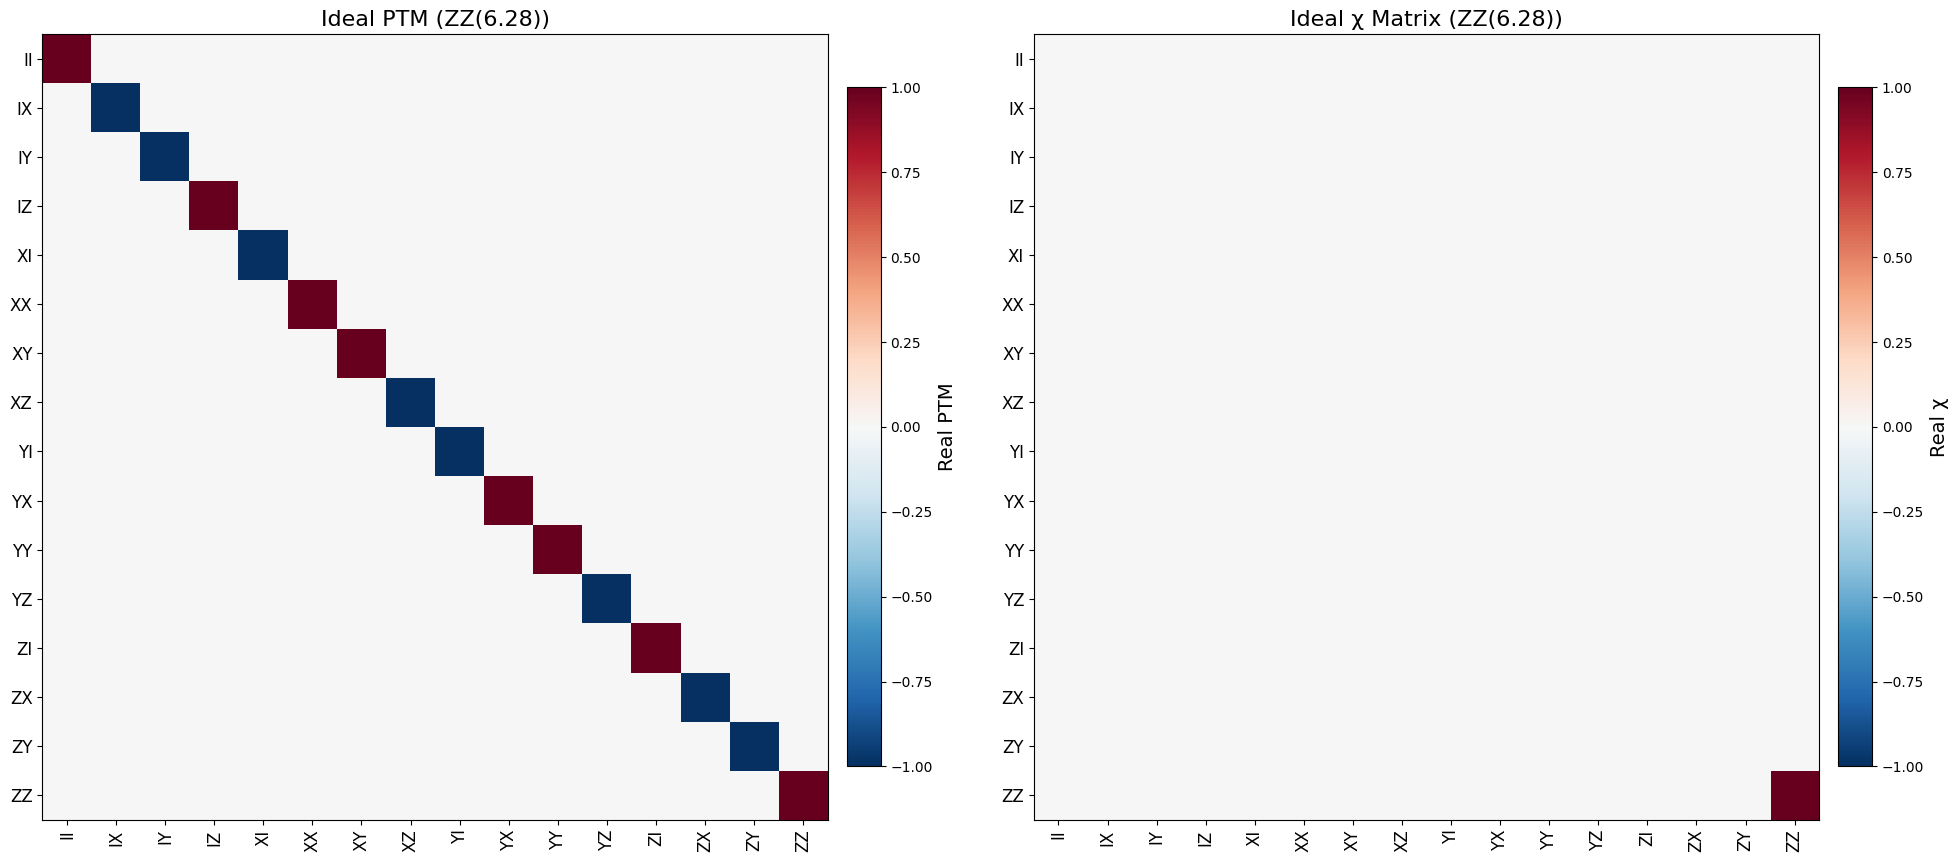

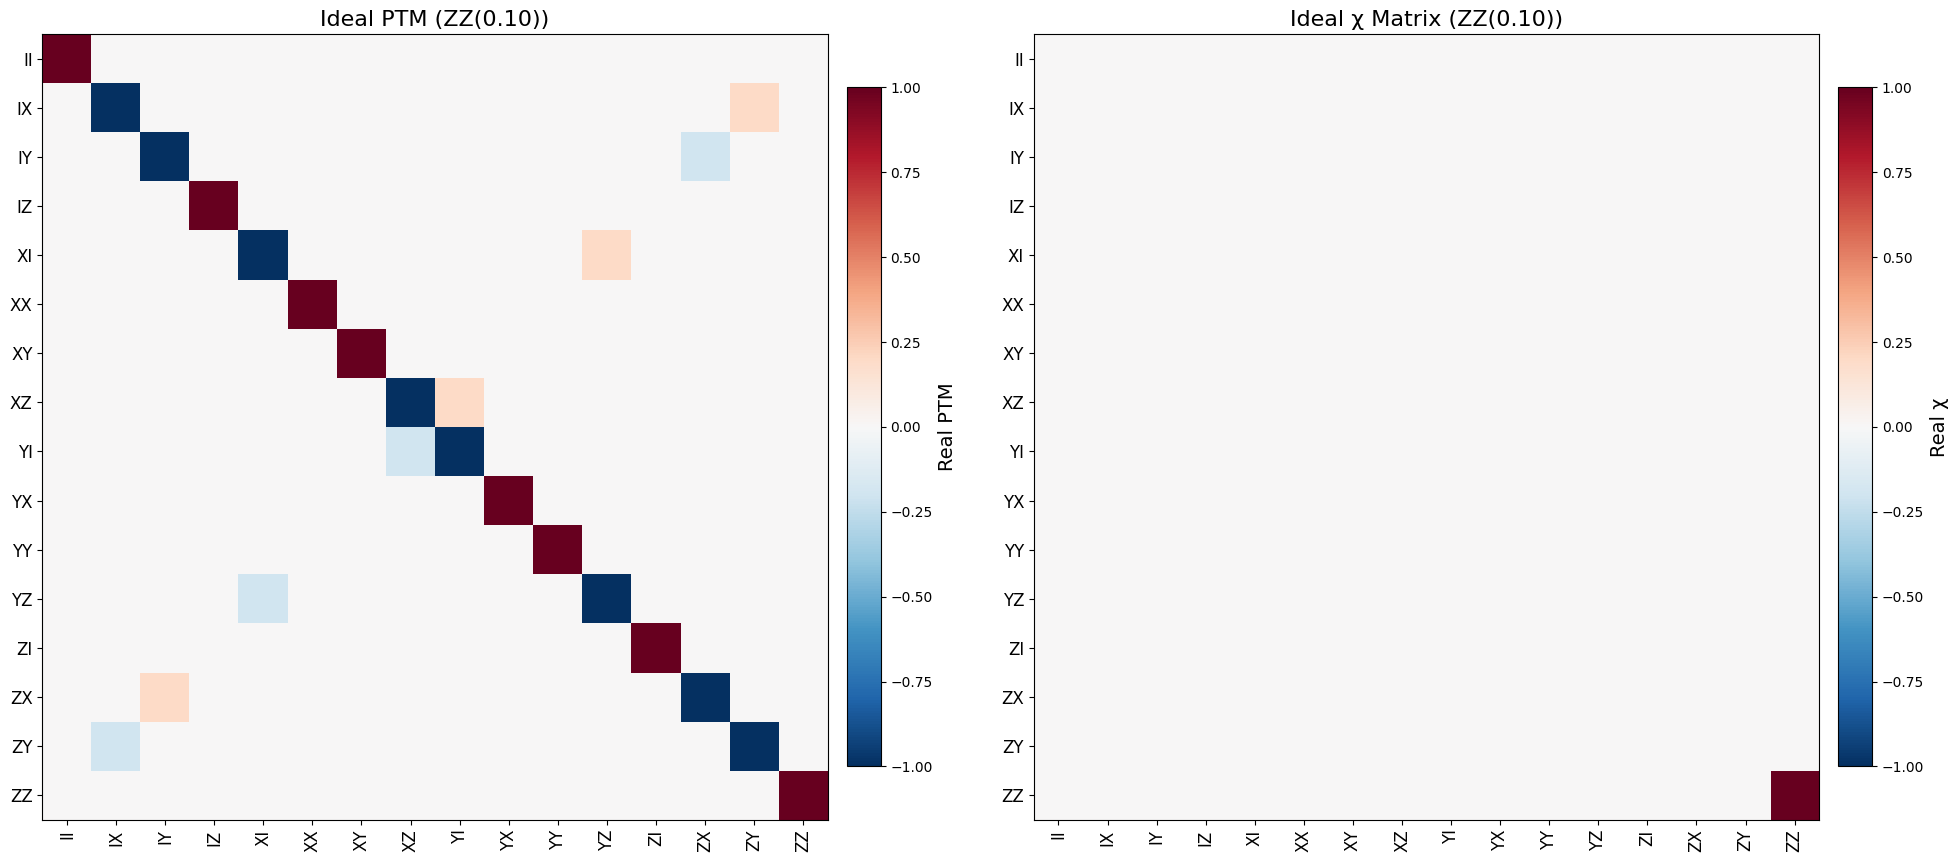

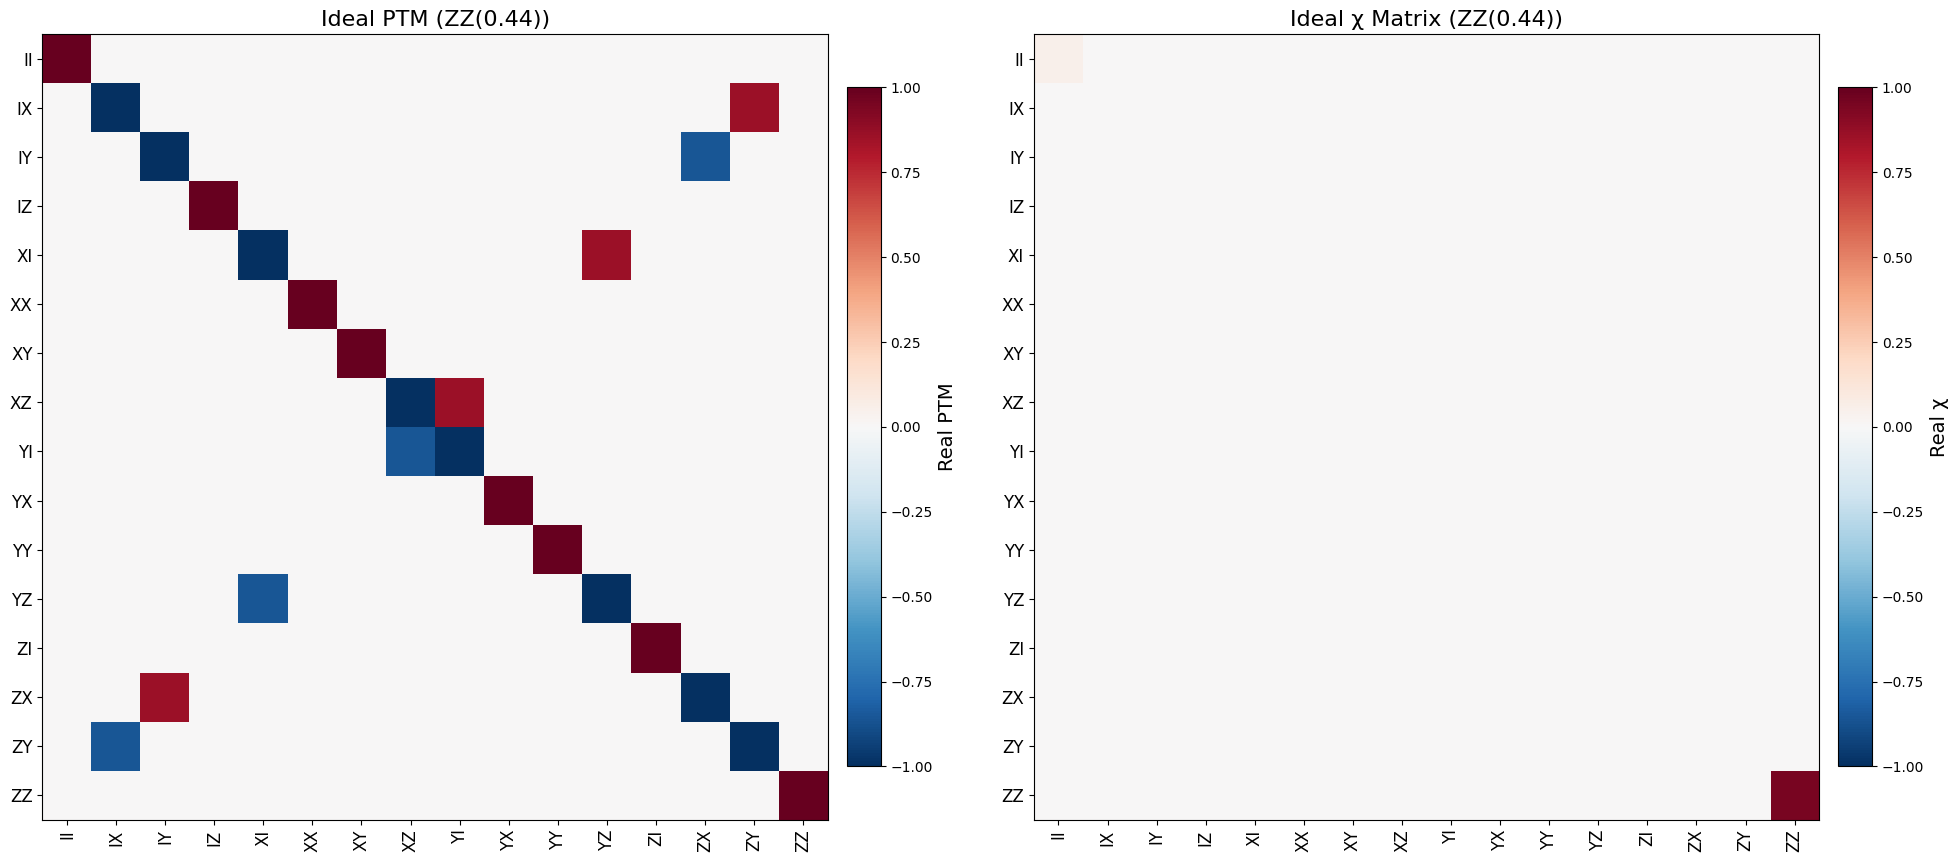

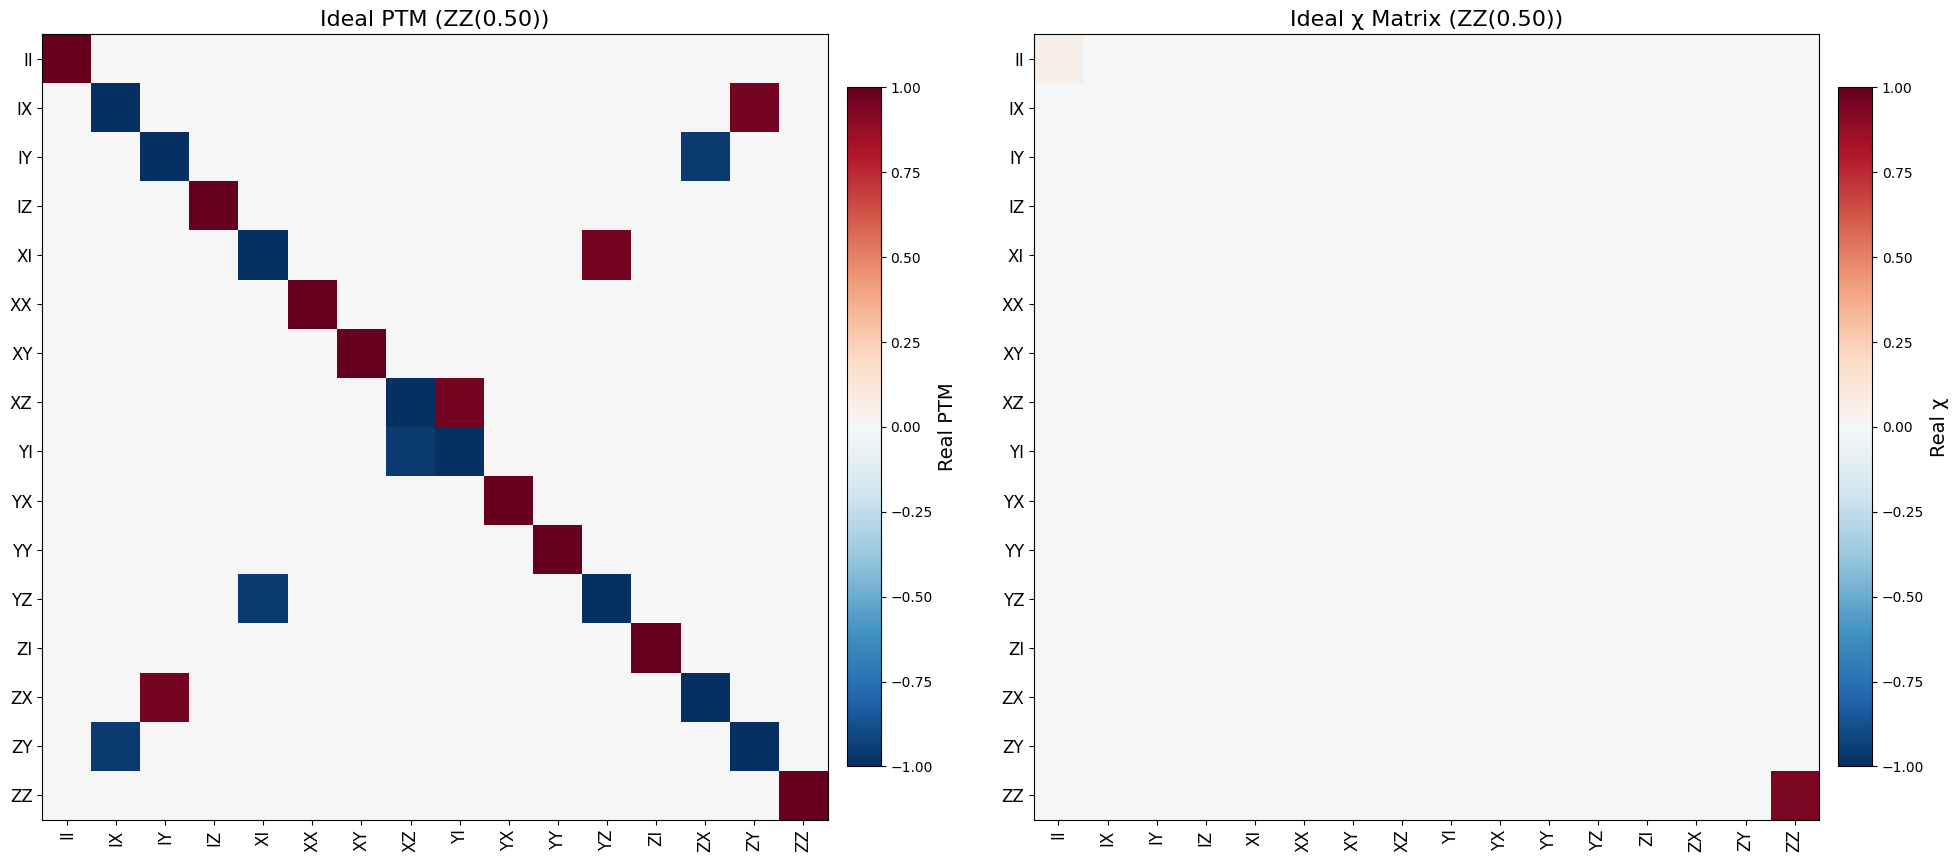

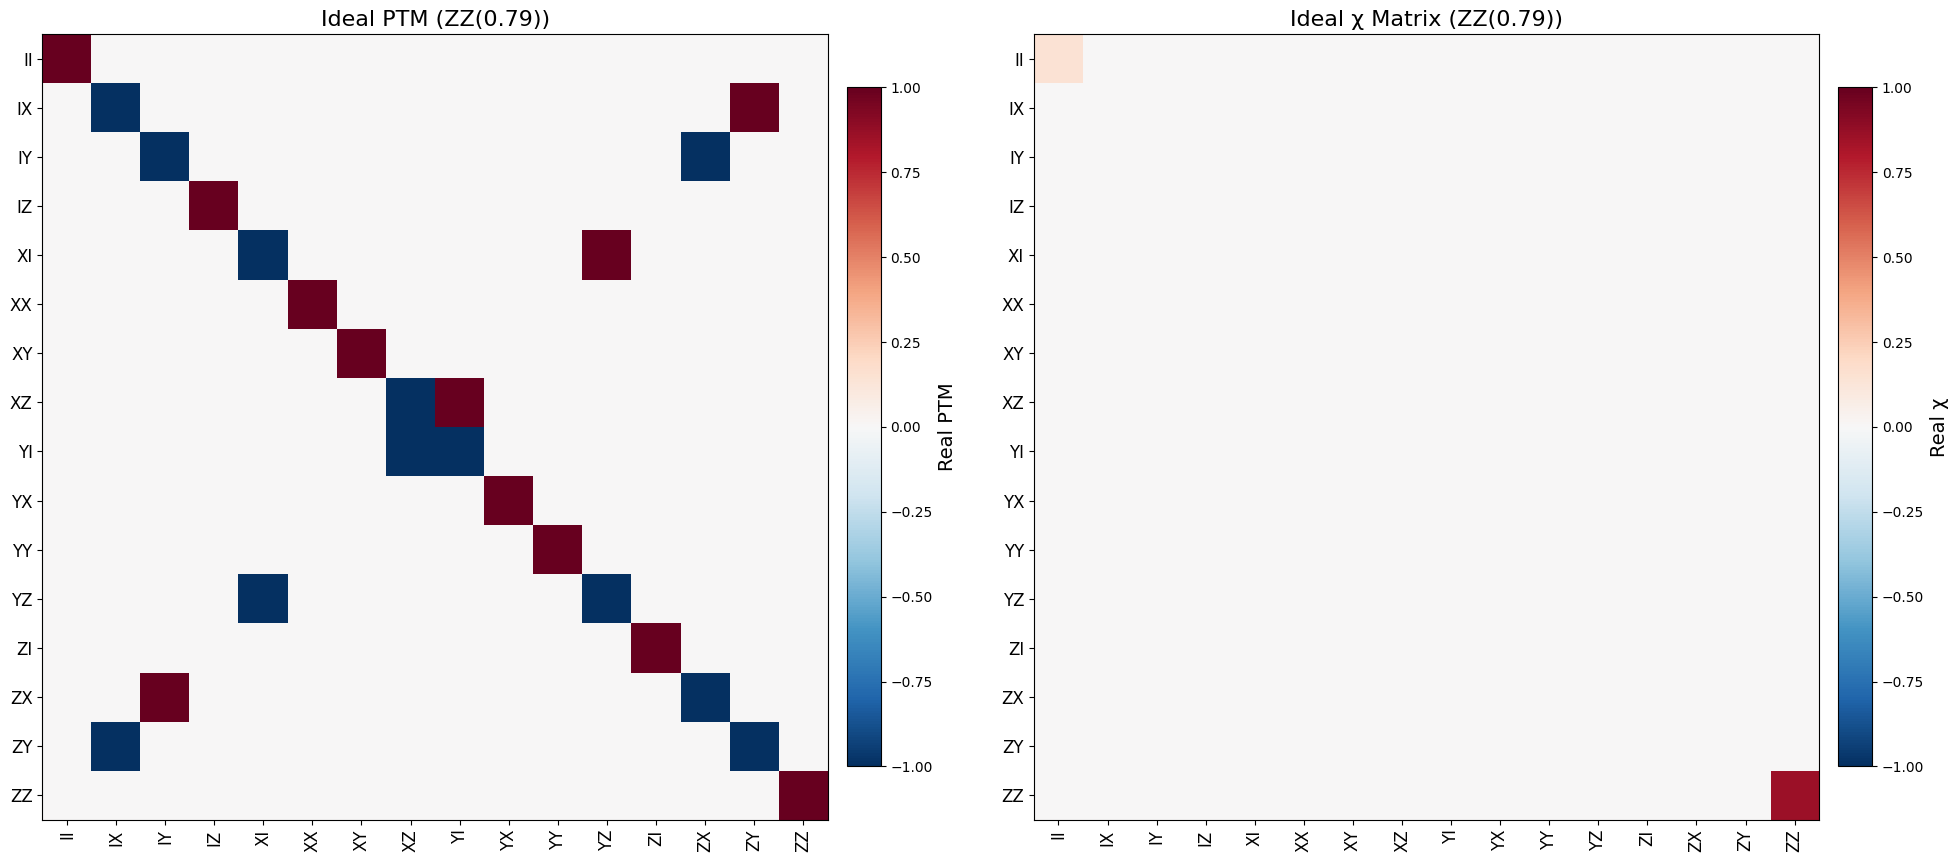

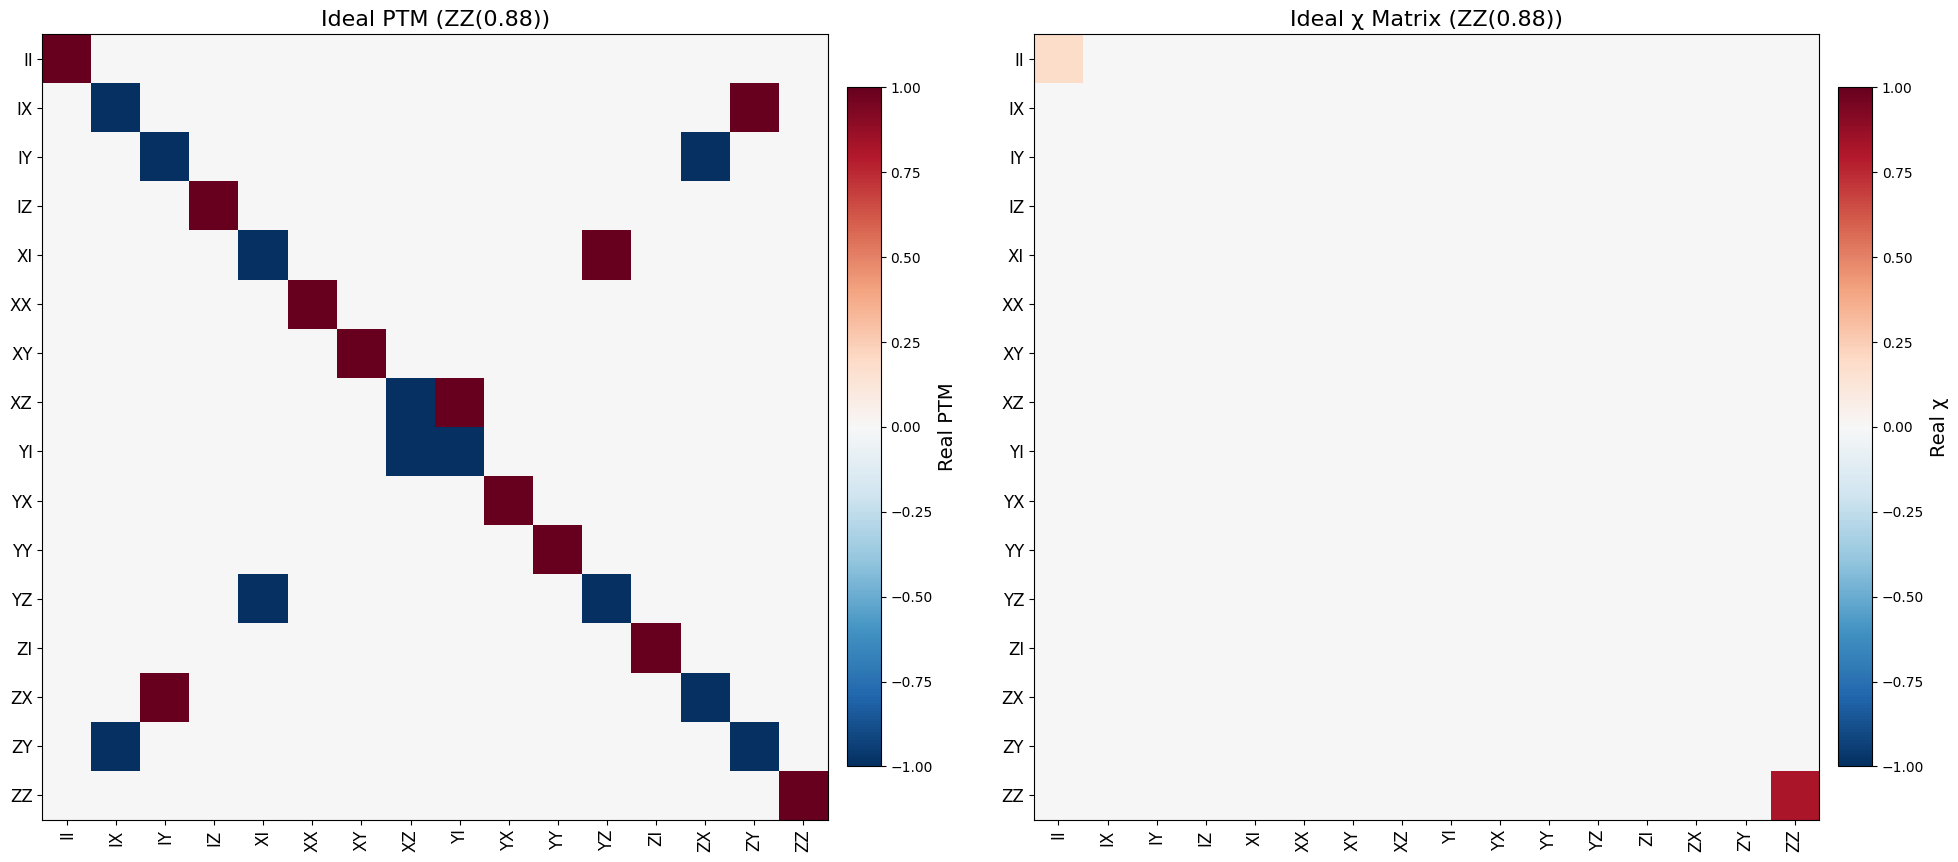

In [ ]:
# --- Convert unitary to PTM --- #
def unitary_to_ptm(U: Qobj):
    paulis = [qeye(2), sigmax(), sigmay(), sigmaz()]
    basis = [Qobj(np.kron(p1.full(), p2.full())) for p1 in paulis for p2 in paulis]
    T = np.zeros((16, 16), dtype=np.complex128)
    for i, Pi in enumerate(basis):
        rho_out = U * Pi * U.dag()
        for j, Pj in enumerate(basis):
            T[j, i] = (Pj.dag() * rho_out).tr() / 2
    return T
# --- Theta values to sweep over --- #
theta_list = [0, np.pi/2, np.pi/4, np.pi, 2*np.pi, 0.1, 0.44, 0.5, 0.79, 0.88]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(zz_unitary(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    chi_ideal = qpt(spre(U_ideal) * spost(U_ideal.dag()), op_basis)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    # PTM plot
    cax1 = ax1.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax1.set_xticks(np.arange(16))
    ax1.set_yticks(np.arange(16))
    ax1.set_xticklabels(ptm_labels, rotation=90, fontsize=12)
    ax1.set_yticklabels(ptm_labels, fontsize=12)
    ax1.set_title(f"Ideal PTM (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # χ matrix plot
    cax2 = ax2.imshow(np.real(chi_ideal), cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax2.set_xticks(np.arange(16))
    ax2.set_yticks(np.arange(16))
    ax2.set_xticklabels(pauli_labels_2q, rotation=90, fontsize=12)
    ax2.set_yticklabels(pauli_labels_2q, fontsize=12)
    ax2.set_title(f"Ideal χ Matrix (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # Colorbars
    fig.colorbar(cax1, ax=ax1, shrink=0.7, pad=0.02).set_label("Real PTM", fontsize=14)
    fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)
    plt.tight_layout()
    plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_11520\3027489898.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


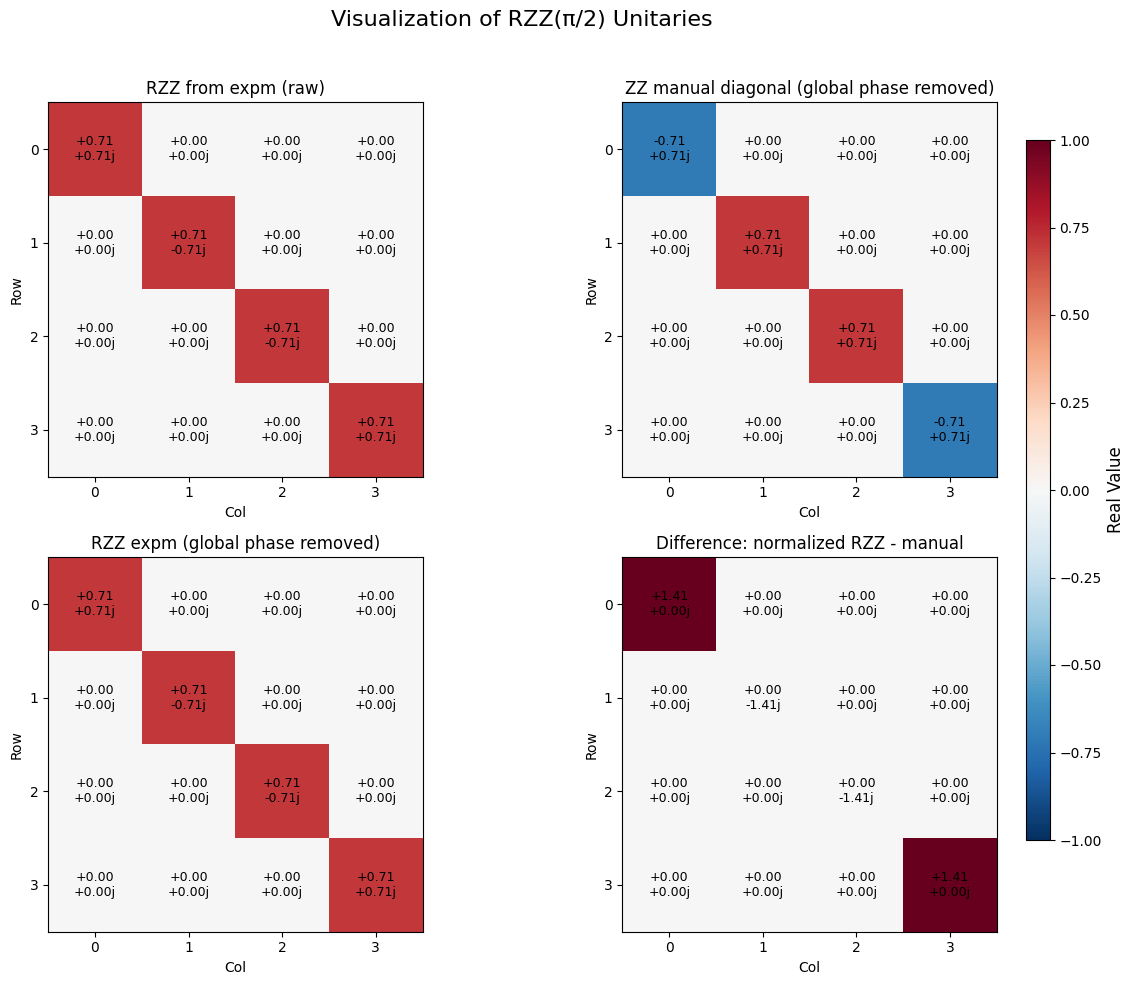

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qutip import sigmaz
# --- Functions --- #
def RZZ(phi):
    ZZ = np.kron(sigmaz().full(), sigmaz().full())
    return expm(1j * phi / 2 * ZZ)
def zz_unitary(phi):
    return np.diag([
        -np.exp(-1j * phi / 2),
         np.exp( 1j * phi / 2),
         np.exp( 1j * phi / 2),
        -np.exp(-1j * phi / 2)
    ])
# --- Parameters --- #
phi = np.pi / 2
np.set_printoptions(precision=4, suppress=True)
# --- Compute unitaries --- #
U_expm = RZZ(phi)
U_diag = zz_unitary(phi)
# Remove global phase from U_expm
global_phase = np.exp(1j * np.angle(np.linalg.det(U_expm)) / 4)
U_expm_normalized = U_expm / global_phase
# Difference matrix
U_diff = U_expm_normalized - U_diag
# --- Plotting --- #
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
titles = [
    "RZZ from expm (raw)",
    "ZZ manual diagonal (global phase removed)",
    "RZZ expm (global phase removed)",
    "Difference: normalized RZZ - manual"
]
mats = [U_expm, U_diag, U_expm_normalized, U_diff]
for ax, mat, title in zip(axs.flatten(), mats, titles):
    im = ax.imshow(np.real(mat), cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title(title, fontsize=12)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    for i in range(4):
        for j in range(4):
            val = mat[i, j]
            ax.text(j, i, f'{val.real:+.2f}\n{val.imag:+.2f}j', ha='center', va='center', fontsize=9)
    ax.set_xlabel('Col')
    ax.set_ylabel('Row')
from matplotlib.colorbar import Colorbar
# Add custom colorbar axis
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Real Value", fontsize=12)
cbar.ax.tick_params(labelsize=10)
plt.suptitle("Visualization of RZZ(π/2) Unitaries", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
def RZZ(phi):
    ZZ = np.kron(sigmaz().full(), sigmaz().full())
    return expm(-1j * phi / 2 * ZZ)
def zz_unitary(phi):
    return np.diag([
        -np.exp(-1j * phi / 2),
         np.exp( 1j * phi / 2),
         np.exp( 1j * phi / 2),
        -np.exp(-1j * phi / 2)
    ])

In [ ]:
def diff(phi):
    return RZZ(phi)-zz_unitary(phi)

In [ ]:
for phi in np.linspace(0,np.pi,100):
    print(diff(phi))

[[2.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 2.-0.j]]
[[1.9997-0.0317j 0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     1.9997-0.0317j]]
[[1.999-0.0635j 0.   +0.j     0.   +0.j     0.   +0.j    ]
 [0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    ]
 [0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    ]
 [0.   +0.j     0.   +0.j     0.   +0.j     1.999-0.0635j]]
[[1.9977-0.0952j 0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     1.9977-0.0952j]]
[[1.996-0.1268j 0.   +0.j     0.   +0.j     0.   +0.j    ]
 [0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    ]
 [0.   +0.j   